In [1]:
#Workforce Attrition & Compensation Analysis
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

sns.set_theme()
pd.set_option("display.max_columns", None)


In [2]:
from google.colab import files
uploaded = files.upload()

Saving hr.csv to hr.csv


In [3]:
df = pd.read_csv(next(iter(uploaded)))

print(df.head())
print("Dataset shape:", df.shape)

   Age Attrition     BusinessTravel  DailyRate              Department  \
0   41       Yes      Travel_Rarely       1102                   Sales   
1   49        No  Travel_Frequently        279  Research & Development   
2   37       Yes      Travel_Rarely       1373  Research & Development   
3   33        No  Travel_Frequently       1392  Research & Development   
4   27        No      Travel_Rarely        591  Research & Development   

   DistanceFromHome  Education EducationField  EmployeeCount  EmployeeNumber  \
0                 1          2  Life Sciences              1               1   
1                 8          1  Life Sciences              1               2   
2                 2          2          Other              1               4   
3                 3          4  Life Sciences              1               5   
4                 2          1        Medical              1               7   

   EnvironmentSatisfaction  Gender  HourlyRate  JobInvolvement  JobLevel  

In [6]:
from google.colab import files
uploaded = files.upload()  # choose the IBM HR CSV
filename = next(iter(uploaded))
df = pd.read_csv(filename)
display(df.head())
print("Shape:", df.shape)


Saving hr.csv to hr (1).csv


,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EmployeeCount,EmployeeNumber,EnvironmentSatisfaction,Gender,HourlyRate,JobInvolvement,JobLevel,JobRole,JobSatisfaction,MaritalStatus,MonthlyIncome,MonthlyRate,NumCompaniesWorked,Over18,OverTime,PercentSalaryHike,PerformanceRating,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
0,41,Yes,Travel_Rarely,1102,Sales,1,2,Life Sciences,1,1,2,Female,94,3,2,Sales Executive,4,Single,5993,19479,8,Y,Yes,11,3,1,80,0,8,0,1,6,4,0,5
1,49,No,Travel_Frequently,279,Research & Development,8,1,Life Sciences,1,2,3,Male,61,2,2,Research Scientist,2,Married,5130,24907,1,Y,No,23,4,4,80,1,10,3,3,10,7,1,7
2,37,Yes,Travel_Rarely,1373,Research & Development,2,2,Other,1,4,4,Male,92,2,1,Laboratory Technician,3,Single,2090,2396,6,Y,Yes,15,3,2,80,0,7,3,3,0,0,0,0
3,33,No,Travel_Frequently,1392,Research & Development,3,4,Life Sciences,1,5,4,Female,56,3,1,Research Scientist,3,Married,2909,23159,1,Y,Yes,11,3,3,80,0,8,3,3,8,7,3,0
4,27,No,Travel_Rarely,591,Research & Development,2,1,Medical,1,7,1,Male,40,3,1,Laboratory Technician,2,Married,3468,16632,9,Y,No,12,3,4,80,1,6,3,3,2,2,2,2


Shape: (1470, 35)


In [8]:
print("Shape:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())
print("\nData types:")
display(df.dtypes.to_frame("dtype"))
print("\nMissing values:")
display(df.isna().sum().to_frame("missing_count"))
print("\nMissing percentage:")
display((df.isna().mean()*100).round(2).to_frame("missing_percent"))
print("\nDuplicate rows:", df.duplicated().sum())


Shape: (1470, 35)

Column names:
['Age', 'Attrition', 'BusinessTravel', 'DailyRate', 'Department', 'DistanceFromHome', 'Education', 'EducationField', 'EmployeeCount', 'EmployeeNumber', 'EnvironmentSatisfaction', 'Gender', 'HourlyRate', 'JobInvolvement', 'JobLevel', 'JobRole', 'JobSatisfaction', 'MaritalStatus', 'MonthlyIncome', 'MonthlyRate', 'NumCompaniesWorked', 'Over18', 'OverTime', 'PercentSalaryHike', 'PerformanceRating', 'RelationshipSatisfaction', 'StandardHours', 'StockOptionLevel', 'TotalWorkingYears', 'TrainingTimesLastYear', 'WorkLifeBalance', 'YearsAtCompany', 'YearsInCurrentRole', 'YearsSinceLastPromotion', 'YearsWithCurrManager']

Data types:


,dtype
Age,int64
Attrition,object
BusinessTravel,object
DailyRate,int64
Department,object
DistanceFromHome,int64
Education,int64
EducationField,object
EmployeeCount,int64
EmployeeNumber,int64



Missing values:


,missing_count
Age,0
Attrition,0
BusinessTravel,0
DailyRate,0
Department,0
DistanceFromHome,0
Education,0
EducationField,0
EmployeeCount,0
EmployeeNumber,0



Missing percentage:


,missing_percent
Age,0.0
Attrition,0.0
BusinessTravel,0.0
DailyRate,0.0
Department,0.0
DistanceFromHome,0.0
Education,0.0
EducationField,0.0
EmployeeCount,0.0
EmployeeNumber,0.0



Duplicate rows: 0


In [9]:
# Check whether each employee number is unique
if "EmployeeNumber" in df.columns:
    print("Unique EmployeeNumber:", df["EmployeeNumber"].nunique())
    print("Duplicate EmployeeNumber:", df["EmployeeNumber"].duplicated().sum())

# Take a look at the different values in text columns
categorical_cols = df.select_dtypes(include="object").columns
for col in categorical_cols:
    print(f"\\n{col}:")
    print(df[col].value_counts(dropna=False))


Unique EmployeeNumber: 1470
Duplicate EmployeeNumber: 0
\nAttrition:
Attrition
No     1233
Yes     237
Name: count, dtype: int64
\nBusinessTravel:
BusinessTravel
Travel_Rarely        1043
Travel_Frequently     277
Non-Travel            150
Name: count, dtype: int64
\nDepartment:
Department
Research & Development    961
Sales                     446
Human Resources            63
Name: count, dtype: int64
\nEducationField:
EducationField
Life Sciences       606
Medical             464
Marketing           159
Technical Degree    132
Other                82
Human Resources      27
Name: count, dtype: int64
\nGender:
Gender
Male      882
Female    588
Name: count, dtype: int64
\nJobRole:
JobRole
Sales Executive              326
Research Scientist           292
Laboratory Technician        259
Manufacturing Director       145
Healthcare Representative    131
Manager                      102
Sales Representative          83
Research Director             80
Human Resources               52
Nam

In [10]:
# Convert Attrition into numbers so it is easier to calculate the rate
df["Attrition_Flag"] = (df["Attrition"].astype(str).str.strip().str.lower() == "yes").astype(int)

# Put employees into groups based on their years at the company
df["Tenure_Group"] = pd.cut(
    df["YearsAtCompany"],
    bins=[-1, 2, 5, 10, 20, np.inf],
    labels=["0-2", "3-5", "6-10", "11-20", "20+"]
)

# Divide monthly income into four groups
df["Pay_Band"] = pd.qcut(
    df["MonthlyIncome"],
    q=4,
    labels=["Low", "Lower-Middle", "Upper-Middle", "High"]
)

# Keep a copy for analysis without the employee ID
analysis_df = df.drop(columns=["EmployeeNumber"], errors="ignore").copy()

display(analysis_df.head())


,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EmployeeCount,EnvironmentSatisfaction,Gender,HourlyRate,JobInvolvement,JobLevel,JobRole,JobSatisfaction,MaritalStatus,MonthlyIncome,MonthlyRate,NumCompaniesWorked,Over18,OverTime,PercentSalaryHike,PerformanceRating,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager,Attrition_Flag,Tenure_Group,Pay_Band
0,41,Yes,Travel_Rarely,1102,Sales,1,2,Life Sciences,1,2,Female,94,3,2,Sales Executive,4,Single,5993,19479,8,Y,Yes,11,3,1,80,0,8,0,1,6,4,0,5,1,6-10,Upper-Middle
1,49,No,Travel_Frequently,279,Research & Development,8,1,Life Sciences,1,3,Male,61,2,2,Research Scientist,2,Married,5130,24907,1,Y,No,23,4,4,80,1,10,3,3,10,7,1,7,0,6-10,Upper-Middle
2,37,Yes,Travel_Rarely,1373,Research & Development,2,2,Other,1,4,Male,92,2,1,Laboratory Technician,3,Single,2090,2396,6,Y,Yes,15,3,2,80,0,7,3,3,0,0,0,0,1,0-2,Low
3,33,No,Travel_Frequently,1392,Research & Development,3,4,Life Sciences,1,4,Female,56,3,1,Research Scientist,3,Married,2909,23159,1,Y,Yes,11,3,3,80,0,8,3,3,8,7,3,0,0,6-10,Low
4,27,No,Travel_Rarely,591,Research & Development,2,1,Medical,1,1,Male,40,3,1,Laboratory Technician,2,Married,3468,16632,9,Y,No,12,3,4,80,1,6,3,3,2,2,2,2,0,0-2,Lower-Middle


In [11]:
total_employees = len(df)
attrition_count = int(df["Attrition_Flag"].sum())
attrition_rate = df["Attrition_Flag"].mean() * 100
average_income = df["MonthlyIncome"].mean()
median_income = df["MonthlyIncome"].median()
average_tenure = df["YearsAtCompany"].mean()

scorecard = pd.DataFrame({
    "Metric": ["Total employees", "Attrition count", "Attrition rate (%)",
               "Average monthly income", "Median monthly income", "Average years at company"],
    "Value": [total_employees, attrition_count, round(attrition_rate, 2),
              round(average_income, 2), round(median_income, 2), round(average_tenure, 2)]
})
display(scorecard)


,Metric,Value
0,Total employees,1470.00
1,Attrition count,237.00
2,Attrition rate (%),16.12
3,Average monthly income,6502.93
4,Median monthly income,4919.00
5,Average years at company,7.01


In [12]:
def attrition_summary(group):
    result = df.groupby(group, observed=True).agg(
        Employees=("Attrition_Flag", "size"),
        Attrition_Count=("Attrition_Flag", "sum"),
        Attrition_Rate=("Attrition_Flag", "mean")
    )
    result["Attrition_Rate"] *= 100
    return result.sort_values("Attrition_Rate", ascending=False).round(2)

department_attrition = attrition_summary("Department")
tenure_attrition = attrition_summary("Tenure_Group")
role_attrition = attrition_summary("JobRole")
overtime_attrition = attrition_summary("OverTime")

display(department_attrition)
display(tenure_attrition)
display(role_attrition)
display(overtime_attrition)


,Employees,Attrition_Count,Attrition_Rate
Department,,,
Sales,446,92,20.63
Human Resources,63,12,19.05
Research & Development,961,133,13.84


,Employees,Attrition_Count,Attrition_Rate
Tenure_Group,,,
0-2,342,102,29.82
3-5,434,60,13.82
6-10,448,55,12.28
20+,66,8,12.12
11-20,180,12,6.67


,Employees,Attrition_Count,Attrition_Rate
JobRole,,,
Sales Representative,83,33,39.76
Laboratory Technician,259,62,23.94
Human Resources,52,12,23.08
Sales Executive,326,57,17.48
Research Scientist,292,47,16.10
Manufacturing Director,145,10,6.90
Healthcare Representative,131,9,6.87
Manager,102,5,4.90
Research Director,80,2,2.50


,Employees,Attrition_Count,Attrition_Rate
OverTime,,,
Yes,416,127,30.53
No,1054,110,10.44


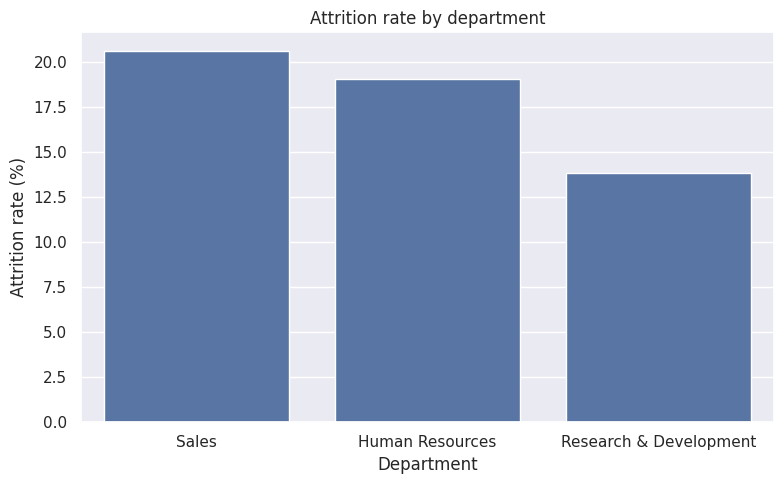

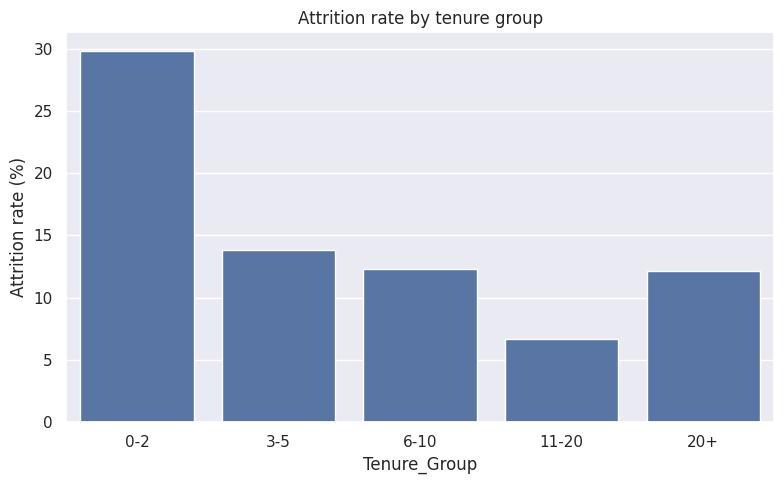

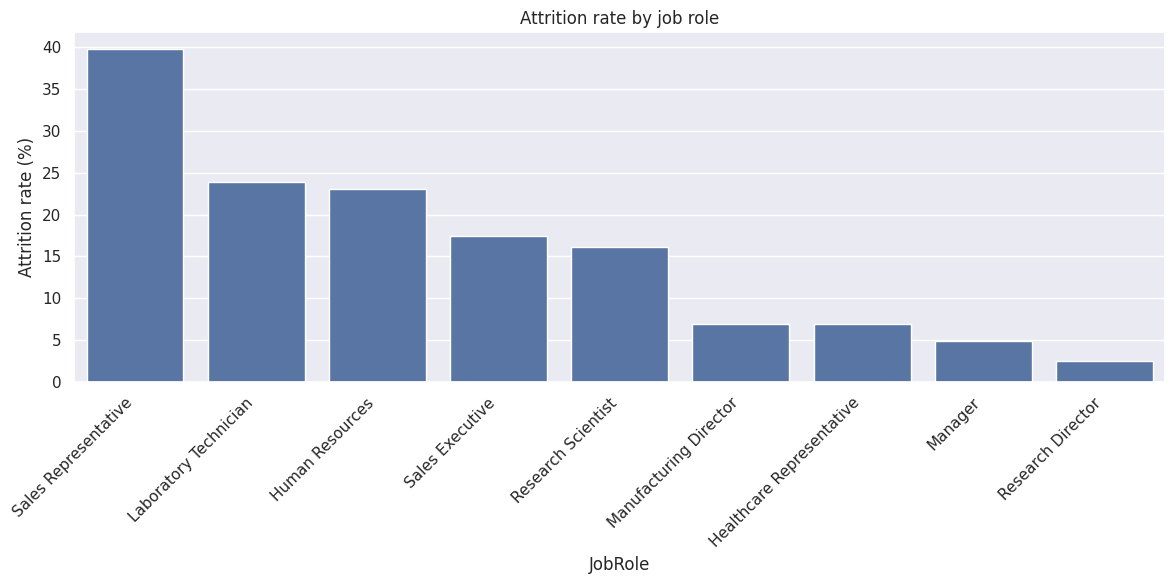

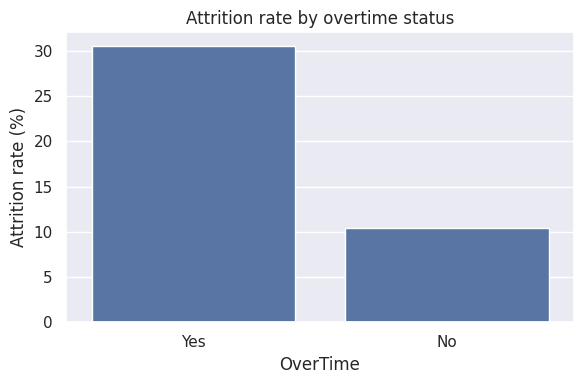

In [13]:
plt.figure(figsize=(8,5))
sns.barplot(data=department_attrition.reset_index(), x="Department", y="Attrition_Rate")
plt.title("Attrition rate by department")
plt.ylabel("Attrition rate (%)")
plt.tight_layout()
plt.show()

plt.figure(figsize=(8,5))
sns.barplot(data=tenure_attrition.reset_index(), x="Tenure_Group", y="Attrition_Rate")
plt.title("Attrition rate by tenure group")
plt.ylabel("Attrition rate (%)")
plt.tight_layout()
plt.show()

plt.figure(figsize=(12,6))
sns.barplot(data=role_attrition.reset_index(), x="JobRole", y="Attrition_Rate")
plt.title("Attrition rate by job role")
plt.xticks(rotation=45, ha="right")
plt.ylabel("Attrition rate (%)")
plt.tight_layout()
plt.show()


plt.figure(figsize=(6,4))
sns.barplot(data=overtime_attrition.reset_index(), x="OverTime", y="Attrition_Rate")
plt.title("Attrition rate by overtime status")
plt.ylabel("Attrition rate (%)")
plt.tight_layout()
plt.show()


In [14]:
yes = df.loc[df["OverTime"] == "Yes", "Attrition_Flag"].to_numpy()
no = df.loc[df["OverTime"] == "No", "Attrition_Flag"].to_numpy()

observed_difference = yes.mean() - no.mean()
print("Attrition rate - overtime (%):", round(yes.mean()*100, 2))
print("Attrition rate - no overtime (%):", round(no.mean()*100, 2))
print("Difference (percentage points):", round(observed_difference*100, 2))

rng = np.random.default_rng(42)
iterations = 5000
bootstrap_diffs = np.empty(iterations)

for i in range(iterations):
    sampled_yes = rng.choice(yes, size=len(yes), replace=True)
    sampled_no = rng.choice(no, size=len(no), replace=True)
    bootstrap_diffs[i] = sampled_yes.mean() - sampled_no.mean()

lower, upper = np.percentile(bootstrap_diffs, [2.5, 97.5])
print("95% bootstrap interval (percentage points):",
      round(lower*100, 2), "to", round(upper*100, 2))


Attrition rate - overtime (%): 30.53
Attrition rate - no overtime (%): 10.44
Difference (percentage points): 20.09
95% bootstrap interval (percentage points): 15.39 to 24.87


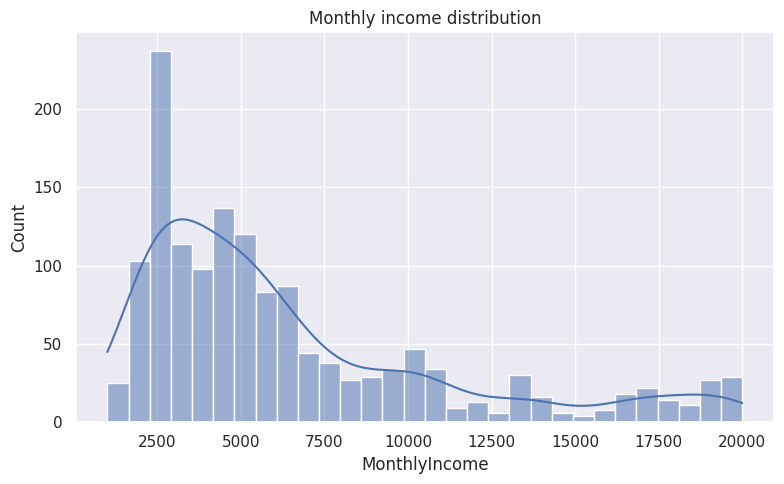

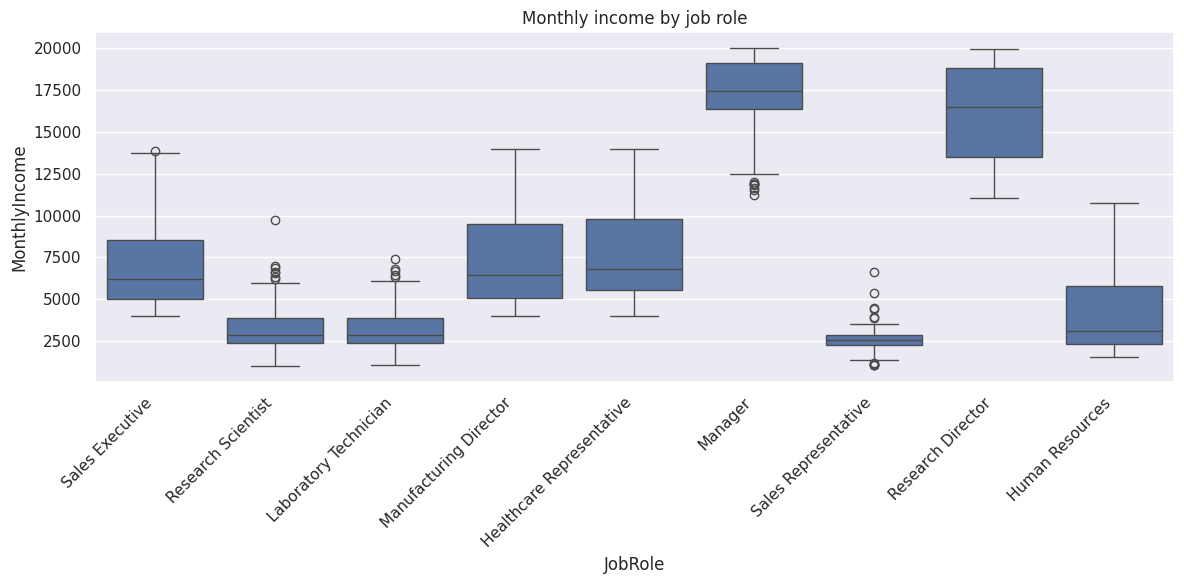

,Employees,Mean_Income,Median_Income,Std_Income,Minimum,Maximum,Coefficient_of_Variation
JobRole,,,,,,,
Healthcare Representative,131,7528.76,6811.0,2542.55,4000,13966,0.34
Human Resources,52,4235.75,3093.0,2438.85,1555,10725,0.58
Laboratory Technician,259,3237.17,2886.0,1150.25,1102,7403,0.36
Manager,102,17181.68,17454.5,2317.20,11244,19999,0.13
Manufacturing Director,145,7295.14,6447.0,2676.75,4011,13973,0.37
Research Director,80,16033.55,16510.0,2827.62,11031,19973,0.18
Research Scientist,292,3239.97,2887.5,1198.12,1009,9724,0.37
Sales Executive,326,6924.28,6231.0,2366.94,4001,13872,0.34
Sales Representative,83,2626.00,2579.0,854.53,1052,6632,0.33


IQR bounds: -5291.0 16581.0
Number of IQR outliers: 114


,JobRole,MonthlyIncome
25,Manager,19094
29,Manager,18947
45,Research Director,19545
62,Research Director,18740
105,Manager,18844
106,Research Director,18172
112,Manager,17328
119,Manager,16959
123,Research Director,19537
147,Manager,17181


In [15]:
plt.figure(figsize=(8,5))
sns.histplot(data=df, x="MonthlyIncome", bins=30, kde=True)
plt.title("Monthly income distribution")
plt.tight_layout()
plt.show()

plt.figure(figsize=(12,6))
sns.boxplot(data=df, x="JobRole", y="MonthlyIncome")
plt.title("Monthly income by job role")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

compensation_summary = df.groupby("JobRole").agg(
    Employees=("MonthlyIncome", "size"),
    Mean_Income=("MonthlyIncome", "mean"),
    Median_Income=("MonthlyIncome", "median"),
    Std_Income=("MonthlyIncome", "std"),
    Minimum=("MonthlyIncome", "min"),
    Maximum=("MonthlyIncome", "max")
)
compensation_summary["Coefficient_of_Variation"] = (
    compensation_summary["Std_Income"] / compensation_summary["Mean_Income"]
)
display(compensation_summary.round(2))

q1 = df["MonthlyIncome"].quantile(0.25)
q3 = df["MonthlyIncome"].quantile(0.75)
iqr = q3 - q1
lower_bound = q1 - 1.5 * iqr
upper_bound = q3 + 1.5 * iqr

income_outliers = df.loc[
    (df["MonthlyIncome"] < lower_bound) | (df["MonthlyIncome"] > upper_bound)
]
print("IQR bounds:", lower_bound, upper_bound)
print("Number of IQR outliers:", len(income_outliers))
display(income_outliers[["JobRole", "MonthlyIncome"]].head(10))


In [16]:
role_summary = df.groupby("JobRole").agg(
    Employees=("JobRole", "size"),
    Average_Income=("MonthlyIncome", "mean"),
    Median_Income=("MonthlyIncome", "median"),
    Average_Tenure=("YearsAtCompany", "mean"),
    Attrition_Count=("Attrition_Flag", "sum")
).round(2)
display(role_summary)

display(df["Pay_Band"].value_counts().sort_index().to_frame("Employees"))


,Employees,Average_Income,Median_Income,Average_Tenure,Attrition_Count
JobRole,,,,,
Healthcare Representative,131,7528.76,6811.0,8.37,9
Human Resources,52,4235.75,3093.0,5.33,12
Laboratory Technician,259,3237.17,2886.0,5.02,62
Manager,102,17181.68,17454.5,14.43,5
Manufacturing Director,145,7295.14,6447.0,7.60,10
Research Director,80,16033.55,16510.0,10.94,2
Research Scientist,292,3239.97,2887.5,5.11,47
Sales Executive,326,6924.28,6231.0,7.50,57
Sales Representative,83,2626.00,2579.0,2.92,33


,Employees
Pay_Band,
Low,369
Lower-Middle,366
Upper-Middle,367
High,368


In [17]:
from pathlib import Path
output_dir = Path("outputs")
output_dir.mkdir(exist_ok=True)

analysis_df.to_csv(output_dir / "deidentified_analysis.csv", index=False)
scorecard.to_csv(output_dir / "attrition_scorecard.csv", index=False)
department_attrition.to_csv(output_dir / "department_attrition.csv")
tenure_attrition.to_csv(output_dir / "tenure_attrition.csv")
role_attrition.to_csv(output_dir / "role_attrition.csv")
overtime_attrition.to_csv(output_dir / "overtime_attrition.csv")
compensation_summary.to_csv(output_dir / "compensation_summary.csv")

import shutil
shutil.make_archive("workforce_analysis_outputs", "zip", output_dir)
print("Saved outputs in outputs/ and created workforce_analysis_outputs.zip")


Saved outputs in outputs/ and created workforce_analysis_outputs.zip


In [18]:
from google.colab import files
files.download("workforce_analysis_outputs.zip")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>